# Đồ án: Nhận diện món ăn & Ước tính Calorie (Food-101)

**Pipeline:** Ảnh món ăn → CNN (ResNet50, transfer learning) → Tên món ăn → Tra bảng calorie → Ước tính calorie

**Trước khi chạy:** vào `Runtime > Change runtime type > GPU` (chọn T4 GPU) để train nhanh hơn nhiều.


## Bước 0: Kiểm tra GPU

In [ ]:
import torch
print("CUDA khả dụng:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Đang dùng thiết bị:", device)


CUDA khả dụng: True
GPU: Tesla T4
Đang dùng thiết bị: cuda


In [ ]:
import os

print("Kiểm tra dataset...")

paths = [
    "/content/food101",
    "/content/data/food-101.zip",
    "/content/food101/food-101/food-101",
    "/content/food101_train",
    "/content/food101_test"
]

for p in paths:
    print(p, "->", os.path.exists(p))

Kiểm tra dataset...
/content/food101 -> False
/content/data/food-101.zip -> False
/content/food101/food-101/food-101 -> False
/content/food101_train -> False
/content/food101_test -> False


## Bước 1: Tải bộ dữ liệu Food-101 từ Kaggle

Cách lấy `kaggle.json` (API key):
1. Vào https://www.kaggle.com/settings > mục **API** > bấm **Create New Token** → tải file `kaggle.json` về máy.
2. Chạy cell dưới, khi được hỏi thì upload file `kaggle.json` vừa tải.


In [ ]:
!pip install -q kaggle

from google.colab import files
print("Hãy chọn file kaggle.json để upload:")
uploaded = files.upload()

import os
os.makedirs("/root/.kaggle", exist_ok=True)
!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json


Hãy chọn file kaggle.json để upload:


Saving kaggle.json to kaggle.json


In [ ]:
import os
os.makedirs("/content/data", exist_ok=True)

!kaggle datasets download -d dansbecker/food-101 -p /content/data

Dataset URL: https://www.kaggle.com/datasets/dansbecker/food-101
License(s): other
100% 9.38G/9.38G [01:37<00:00, 103MB/s]



In [ ]:
!rm -rf /content/food101
!mkdir -p /content/food101
!unzip -q -o /content/data/food-101.zip -d /content/food101

In [ ]:
import os

for root, dirs, files in os.walk("/content/food101"):
    if "images" in dirs and "meta" in dirs:
        print("✅ Dataset:", root)
        print("images:", os.path.exists(os.path.join(root, "images")))
        print("meta:", os.path.exists(os.path.join(root, "meta")))
        break

✅ Dataset: /content/food101/food-101/__MACOSX/food-101
images: True
meta: True


In [ ]:
import os

os.makedirs("/root/.kaggle", exist_ok=True)
!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

print(os.path.exists("/root/.kaggle/kaggle.json"))

True


In [ ]:
import os

os.makedirs("/content/data", exist_ok=True)

!kaggle datasets download -d dansbecker/food-101 -p /content/data

print("=== KIỂM TRA FILE ===")
!ls -lh /content/data

Dataset URL: https://www.kaggle.com/datasets/dansbecker/food-101
License(s): other
food-101.zip: Skipping, found more recently modified local copy (use --force to force download)
=== KIỂM TRA FILE ===
total 9.4G
-rw-r--r-- 1 root root 9.4G Nov 21  2019 food-101.zip


In [ ]:
import os

ZIP_PATH = "/content/data/food-101.zip"
EXTRACT_PATH = "/content/food101"

os.makedirs(EXTRACT_PATH, exist_ok=True)

!unzip -q -o /content/data/food-101.zip -d /content/food101

print("✅ Giải nén xong!")

✅ Giải nén xong!


In [ ]:
import os

print("=== KIỂM TRA FOOD-101 ===")

found = False

for root, dirs, files in os.walk("/content/food101"):
    if "images" in dirs and "meta" in dirs:
        print("✅ Đã tìm thấy dataset tại:")
        print(root)
        print()
        print("images:", os.path.exists(os.path.join(root, "images")))
        print("meta:", os.path.exists(os.path.join(root, "meta")))
        found = True
        break

if not found:
    print("❌ Chưa tìm thấy thư mục images + meta")

=== KIỂM TRA FOOD-101 ===
✅ Đã tìm thấy dataset tại:
/content/food101/food-101/__MACOSX/food-101

images: True
meta: True


In [ ]:
# Tải dataset Food-101 (khoảng 5GB, có thể mất vài phút)
!kaggle datasets download -d dansbecker/food-101 -p /content/data --unzip
!ls /content/data


Dataset URL: https://www.kaggle.com/datasets/dansbecker/food-101
License(s): other
food-101.zip: Skipping, found more recently modified local copy (use --force to force download)
food-101.zip


In [ ]:
!rm -rf /content/data
!mkdir -p /content/data
!kaggle datasets download -d dansbecker/food-101 -p /content/data

Dataset URL: https://www.kaggle.com/datasets/dansbecker/food-101
License(s): other
100% 9.38G/9.38G [02:35<00:00, 64.7MB/s]



In [ ]:
!unzip -q /content/data/food-101.zip -d /content/data/

replace /content/data/food-101.zip? [y]es, [n]o, [A]ll, [N]one, [r]ename: n


In [ ]:
!mkdir -p /content/data
!kaggle datasets download -d dansbecker/food-101 -p /content/data

Dataset URL: https://www.kaggle.com/datasets/dansbecker/food-101
License(s): other
food-101.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!rm -rf /content/food101
!mkdir -p /content/food101
!unzip -q -o /content/data/food-101.zip -d /content/food101

In [ ]:
!find /content/food101 -maxdepth 3 -type d | head -20

/content/food101
/content/food101/food-101
/content/food101/food-101/__MACOSX
/content/food101/food-101/__MACOSX/food-101
/content/food101/food-101/food-101
/content/food101/food-101/food-101/images
/content/food101/food-101/food-101/meta


In [ ]:
import os

print("Các thư mục trong /content:")
for root, dirs, files in os.walk("/content"):
    if "images" in dirs and "meta" in dirs:
        print("ĐÃ TÌM THẤY:", root)

Các thư mục trong /content:
ĐÃ TÌM THẤY: /content/data/food-101/__MACOSX/food-101
ĐÃ TÌM THẤY: /content/data/food-101/food-101
ĐÃ TÌM THẤY: /content/food101/food-101/__MACOSX/food-101
ĐÃ TÌM THẤY: /content/food101/food-101/food-101


In [ ]:
!find /content -type d -name images | head -20

/content/data/food-101/__MACOSX/food-101/images
/content/data/food-101/food-101/images
/content/food101/food-101/__MACOSX/food-101/images
/content/food101/food-101/food-101/images


## Bước 2: Kiểm tra cấu trúc dữ liệu và chia train/test

Food-101 gốc có cấu trúc `images/<class>/*.jpg` và danh sách chia train/test nằm trong
`meta/train.txt`, `meta/test.txt`. Cell dưới tự động tạo thư mục `train/` và `test/`
theo chuẩn `ImageFolder` mà PyTorch cần (dùng symlink để không tốn thêm dung lượng ổ đĩa).


In [ ]:
import os

# Tự động tìm thư mục Food-101
DATA_ROOT = None

for root, dirs, files in os.walk("/content/food101"):
    if "images" in dirs and "meta" in dirs:
        DATA_ROOT = root
        break

if DATA_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục Food-101 có images/ và meta/")

print("✅ Đã tìm thấy Food-101 tại:")
print(DATA_ROOT)

print("\nCác thư mục bên trong:")
print(os.listdir(DATA_ROOT))

print("\nCó images:", os.path.exists(os.path.join(DATA_ROOT, "images")))
print("Có meta:", os.path.exists(os.path.join(DATA_ROOT, "meta")))

✅ Đã tìm thấy Food-101 tại:
/content/food101/food-101/__MACOSX/food-101

Các thư mục bên trong:
['images', '._license_agreement.txt', '._.DS_Store', '._meta', 'meta', '._images', '._README.txt']

Có images: True
Có meta: True


In [ ]:
import os

print("=== KIỂM TRA /content ===")
print(os.listdir("/content"))

print("\n=== TÌM FILE FOOD-101 ===")
for root, dirs, files in os.walk("/content"):
    if "images" in dirs:
        print("Có images tại:", os.path.join(root, "images"))
    if "meta" in dirs:
        print("Có meta tại:", os.path.join(root, "meta"))

print("\n=== TÌM FILE ZIP ===")
for root, dirs, files in os.walk("/content"):
    for f in files:
        if "food-101" in f.lower() and f.endswith(".zip"):
            print("Có ZIP:", os.path.join(root, f))

=== KIỂM TRA /content ===
['.config', 'data', 'kaggle.json', 'food101', 'sample_data']

=== TÌM FILE FOOD-101 ===
Có images tại: /content/data/food-101/__MACOSX/food-101/images
Có meta tại: /content/data/food-101/__MACOSX/food-101/meta
Có images tại: /content/data/food-101/food-101/images
Có meta tại: /content/data/food-101/food-101/meta
Có images tại: /content/food101/food-101/__MACOSX/food-101/images
Có meta tại: /content/food101/food-101/__MACOSX/food-101/meta
Có images tại: /content/food101/food-101/food-101/images
Có meta tại: /content/food101/food-101/food-101/meta

=== TÌM FILE ZIP ===
Có ZIP: /content/data/food-101.zip
Có ZIP: /content/food101/food-101.zip


In [ ]:
import os

# Đường dẫn chính xác của Food-101
DATA_ROOT = "/content/food101/food-101/food-101"

IMAGES_DIR = os.path.join(DATA_ROOT, "images")
META_DIR = os.path.join(DATA_ROOT, "meta")

TRAIN_META = os.path.join(META_DIR, "train.txt")
TEST_META = os.path.join(META_DIR, "test.txt")

TRAIN_DIR = "/content/food101_train"
TEST_DIR = "/content/food101_test"


def build_split(meta_file, output_dir):
    print("Đang tạo:", output_dir)

    with open(meta_file, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    count = 0

    for line in lines:
        # Ví dụ: apple_pie/1005649
        parts = line.split("/")
        class_name = parts[0]
        image_name = parts[1]

        src = os.path.join(
            IMAGES_DIR,
            class_name,
            image_name + ".jpg"
        )

        dst_dir = os.path.join(output_dir, class_name)
        os.makedirs(dst_dir, exist_ok=True)

        dst = os.path.join(dst_dir, image_name + ".jpg")

        # Tạo symlink, không copy ảnh nên không tốn thêm 5GB
        if not os.path.exists(dst):
            os.symlink(src, dst)

        count += 1

        if count % 10000 == 0:
            print("Đã xử lý:", count)

    print("Hoàn thành:", count, "ảnh")


# Tạo train
build_split(TRAIN_META, TRAIN_DIR)

# Tạo test
build_split(TEST_META, TEST_DIR)

print("\n✅ ĐÃ CHIA DATASET XONG!")
print("Train:", TRAIN_DIR)
print("Test :", TEST_DIR)

Đang tạo: /content/food101_train
Đã xử lý: 10000
Đã xử lý: 20000
Đã xử lý: 30000
Đã xử lý: 40000
Đã xử lý: 50000
Đã xử lý: 60000
Đã xử lý: 70000
Hoàn thành: 75750 ảnh
Đang tạo: /content/food101_test
Đã xử lý: 10000
Đã xử lý: 20000
Hoàn thành: 25250 ảnh

✅ ĐÃ CHIA DATASET XONG!
Train: /content/food101_train
Test : /content/food101_test


In [ ]:
import os

print("Có thư mục Kaggle:", os.path.exists("/root/.kaggle"))
print("Có kaggle.json:", os.path.exists("/root/.kaggle/kaggle.json"))

Có thư mục Kaggle: True
Có kaggle.json: True


## Bước 3: Tạo bảng tra cứu calorie (`calories.csv`)

In [12]:
import pandas as pd

calorie_df = pd.read_csv("/content/calories.csv")

print("✅ Đã nạp dữ liệu calorie")
print("Số món:", len(calorie_df))
print(calorie_df.head())

✅ Đã nạp dữ liệu calorie
Số món: 101
       class_name  calories_per_100g  typical_portion_g
0       apple_pie                237                125
1  baby_back_ribs                278                200
2         baklava                428                 60
3  beef_carpaccio                140                100
4    beef_tartare                150                120


In [11]:
calories_csv_content = '''class_name,calories_per_100g,typical_portion_g
apple_pie,237,125
baby_back_ribs,278,200
baklava,428,60
beef_carpaccio,140,100
beef_tartare,150,120
beet_salad,60,150
beignets,342,50
bibimbap,180,450
bread_pudding,153,150
breakfast_burrito,220,250
bruschetta,140,80
caesar_salad,150,200
cannoli,320,60
caprese_salad,180,150
carrot_cake,340,100
ceviche,90,150
cheesecake,321,100
cheese_plate,350,80
chicken_curry,165,300
chicken_quesadilla,280,200
chicken_wings,290,150
chocolate_cake,371,100
chocolate_mousse,280,120
churros,375,80
clam_chowder,90,250
club_sandwich,250,250
crab_cakes,220,100
creme_brulee,310,110
croque_madame,290,180
cup_cakes,350,60
deviled_eggs,180,50
donuts,452,60
dumplings,150,150
edamame,120,100
eggs_benedict,240,200
escargots,90,60
falafel,333,100
filet_mignon,271,200
fish_and_chips,230,300
foie_gras,462,50
french_fries,312,150
french_onion_soup,80,300
french_toast,229,150
fried_calamari,175,150
fried_rice,163,250
frozen_yogurt,127,150
garlic_bread,350,80
gnocchi,131,200
greek_salad,110,200
grilled_cheese_sandwich,290,150
grilled_salmon,208,180
guacamole,150,60
gyoza,180,150
hamburger,295,220
hot_and_sour_soup,45,300
hot_dog,290,100
huevos_rancheros,150,300
hummus,166,60
ice_cream,207,100
lasagna,135,250
lobster_bisque,140,250
lobster_roll_sandwich,250,200
macaroni_and_cheese,164,250
macarons,410,30
miso_soup,40,250
mussels,86,200
nachos,306,150
omelette,154,150
onion_rings,411,100
oysters,68,100
pad_thai,180,300
paella,150,350
pancakes,227,150
panna_cotta,220,100
peking_duck,337,150
pho,60,450
pizza,266,150
pork_chop,231,200
poutine,290,300
prime_rib,270,220
pulled_pork_sandwich,270,220
ramen,436,450
ravioli,175,220
red_velvet_cake,367,100
risotto,166,250
samosa,262,60
sashimi,127,120
scallops,111,100
seaweed_salad,45,100
shrimp_and_grits,180,300
spaghetti_bolognese,151,300
spaghetti_carbonara,193,300
spring_rolls,150,80
steak,271,220
strawberry_shortcake,290,120
sushi,150,200
tacos,226,150
takoyaki,190,120
tiramisu,283,100
tuna_tartare,144,120
waffles,291,120
'''

with open("/content/calories.csv", "w") as f:
    f.write(calories_csv_content)

import pandas as pd
calorie_df = pd.read_csv("/content/calories.csv")
print(f"Đã tạo bảng calorie cho {len(calorie_df)} loại món.")
calorie_df.head()


Đã tạo bảng calorie cho 101 loại món.


,class_name,calories_per_100g,typical_portion_g
0,apple_pie,237,125
1,baby_back_ribs,278,200
2,baklava,428,60
3,beef_carpaccio,140,100
4,beef_tartare,150,120


## Bước 4: Chuẩn bị DataLoader

**Lưu ý:** Nếu chỉ để thử nghiệm nhanh (debug pipeline) trước khi train full 101 lớp,
bạn có thể đặt `SUBSET_CLASSES = 10` để train thử trên 10 lớp cho nhanh, sau đó đổi
thành `None` để train đầy đủ 101 lớp.


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMG_SIZE = 224
BATCH_SIZE = 32
SUBSET_CLASSES = None   # đổi thành ví dụ 10 để thử nhanh, None = dùng toàn bộ 101 lớp

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
val_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds = datasets.ImageFolder(TEST_DIR, transform=val_tf)

if SUBSET_CLASSES:
    keep_classes = set(train_ds.classes[:SUBSET_CLASSES])
    train_idx = [i for i, (_, y) in enumerate(train_ds.samples) if train_ds.classes[y] in keep_classes]
    val_idx = [i for i, (_, y) in enumerate(val_ds.samples) if val_ds.classes[y] in keep_classes]
    train_ds = torch.utils.data.Subset(train_ds, train_idx)
    val_ds = torch.utils.data.Subset(val_ds, val_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

classes = train_ds.dataset.classes if SUBSET_CLASSES else train_ds.classes
print("Số lớp sẽ train:", len(classes))
print("Số ảnh train:", len(train_ds), "| Số ảnh val:", len(val_ds))


Số lớp sẽ train: 101
Số ảnh train: 75750 | Số ảnh val: 25250


## Bước 5: Xây dựng model (ResNet50, transfer learning)

In [ ]:
import torch.nn as nn
from torchvision import models

def build_model(num_classes, freeze_backbone=True):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, num_classes)
    )
    return model

model = build_model(num_classes=len(classes)).to(device)
print(model.fc)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 136MB/s]


Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=2048, out_features=101, bias=True)
)


## Bước 6: Huấn luyện model

In [ ]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from tqdm import tqdm
from google.colab import files

NUM_EPOCHS = 5
LR = 1e-3

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR
)

scheduler = lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

dataloaders = {
    "train": train_loader,
    "val": val_loader
}

best_acc = 0.0
best_weights = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 30)

    for phase in ["train", "val"]:

        if phase == "train":
            model.train()
        else:
            model.eval()

        running_loss = 0.0
        running_corrects = 0
        total = 0

        loader = dataloaders[phase]

        for inputs, labels in tqdm(loader, desc=phase):

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            with torch.set_grad_enabled(phase == "train"):

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                _, preds = torch.max(outputs, 1)

                if phase == "train":
                    loss.backward()
                    optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)
            total += inputs.size(0)

        epoch_loss = running_loss / total
        epoch_acc = (running_corrects.double() / total).item()

        print(
            f"{phase} Loss: {epoch_loss:.4f} "
            f"Acc: {epoch_acc:.4f}"
        )

        history[f"{phase}_loss"].append(epoch_loss)
        history[f"{phase}_acc"].append(epoch_acc)

        if phase == "val":

            scheduler.step(epoch_acc)

            if epoch_acc > best_acc:
                best_acc = epoch_acc
                best_weights = copy.deepcopy(model.state_dict())

    # ===== LƯU CHECKPOINT SAU MỖI EPOCH =====

    checkpoint_path = f"/content/checkpoint_epoch_{epoch+1}.pth"

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_acc": best_acc,
        "history": history,
        "classes": classes
    }, checkpoint_path)

    print(f"✅ Đã lưu checkpoint Epoch {epoch+1}")

    # Tải checkpoint về máy để Colab reset vẫn không mất
    files.download(checkpoint_path)


# Load model tốt nhất
model.load_state_dict(best_weights)

torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "best_acc": best_acc
}, "/content/best_model.pth")

print("\n==========================")
print(f"✅ Độ chính xác tốt nhất: {best_acc:.4f}")
print("✅ Đã lưu best_model.pth")


Epoch 1/5
------------------------------


train: 100%|██████████| 2368/2368 [10:21<00:00,  3.81it/s]


train Loss: 3.1393 Acc: 0.3679


val: 100%|██████████| 790/790 [02:42<00:00,  4.85it/s]


val Loss: 2.2360 Acc: 0.6024
✅ Đã lưu checkpoint Epoch 1


...

val: 100%|██████████| 790/790 [02:35<00:00,  5.08it/s]


val Loss: 2.0153 Acc: 0.6624
✅ Đã lưu checkpoint Epoch 5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Độ chính xác tốt nhất: 0.6624
✅ Đã lưu best_model.pth


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving checkpoint_epoch_5.pth to checkpoint_epoch_5.pth


## Bước 7: Vẽ biểu đồ Loss / Accuracy (để đưa vào báo cáo)

In [ ]:
history = checkpoint["history"]

print(history)

{'train_loss': [3.1393162687509366, 2.7399777057257424, 2.688158668694323, 2.661017790577199, 2.6498252301105967], 'train_acc': [0.3679075907590759, 0.4603564356435644, 0.4732937293729373, 0.48234983498349837, 0.4848712871287129], 'val_loss': [2.2360361006708427, 2.0988544609900748, 2.0464219601319567, 2.040244563187703, 2.015305157009918], 'val_acc': [0.6024158415841584, 0.6357623762376238, 0.6544554455445545, 0.6527920792079208, 0.6623762376237624]}


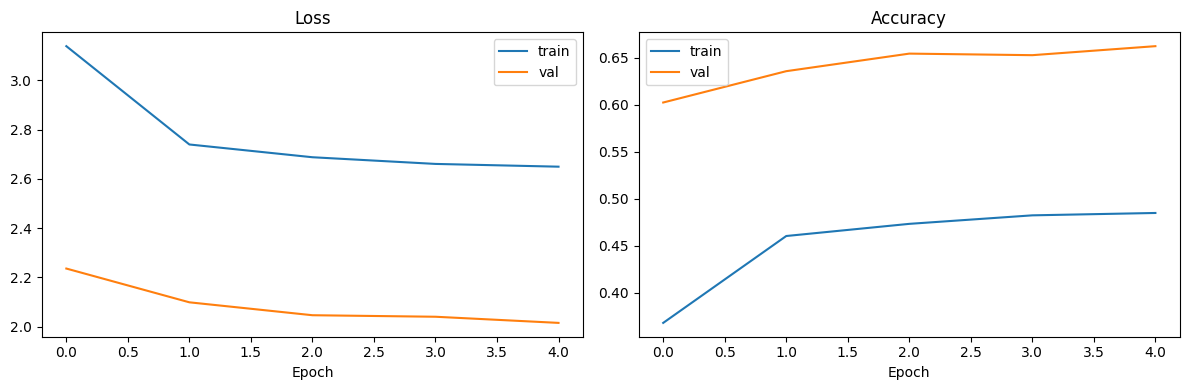

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()


## Bước 8: Lưu model (nên lưu vào Google Drive để không mất khi Colab reset)

In [ ]:
import torch
from google.colab import files

torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "best_acc": best_acc
}, "/content/best_model.pth")

print("✅ Đã lưu best_model.pth")

files.download("/content/best_model.pth")

✅ Đã lưu best_model.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Bước 9: Đánh giá model (Top-1, Top-5 accuracy)

In [5]:
import torch
from tqdm import tqdm

def evaluate_topk(model, loader, device, k_values=(1, 5)):
    model.eval()

    correct = {k: 0 for k in k_values}
    total = 0

    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc="Đánh giá"):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            maxk = max(k_values)
            _, pred = outputs.topk(maxk, dim=1)

            pred = pred.t()

            correct_mat = pred.eq(
                labels.view(1, -1).expand_as(pred)
            )

            for k in k_values:
                correct[k] += correct_mat[:k].reshape(-1).float().sum().item()

            total += labels.size(0)

    return {k: correct[k] / total for k in k_values}


acc = evaluate_topk(model, val_loader, device)

print("\n===== KẾT QUẢ ĐÁNH GIÁ =====")
print(f"Top-1 Accuracy: {acc[1] * 100:.2f}%")
print(f"Top-5 Accuracy: {acc[5] * 100:.2f}%")

Đánh giá:   0%|          | 0/198 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Đánh giá:   2%|▏         | 4/198 [02:23<1:56:16, 35.96s/it]


KeyboardInterrupt: 

## Bước 10: Dự đoán món ăn từ ảnh + tính calorie

Chọn 1 ảnh món ăn để test:


Saving OIP (1).webp to OIP (1) (5).webp


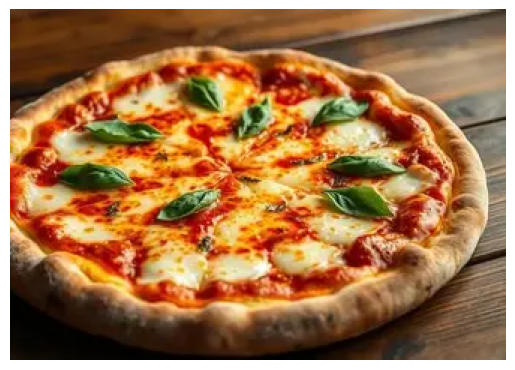

Top dự đoán:
  pizza: 96.3%  -> ~399.0 kcal (khẩu phần 150.0g)
  french_onion_soup: 1.1%  -> ~240.0 kcal (khẩu phần 300.0g)
  lasagna: 0.7%  -> ~337.5 kcal (khẩu phần 250.0g)


In [27]:
from PIL import Image

def get_calorie_info(class_name, calorie_df):
    row = calorie_df[calorie_df["class_name"] == class_name]
    if row.empty:
        return None
    row = row.iloc[0]
    return {
        "calories_per_100g": float(row["calories_per_100g"]),
        "typical_portion_g": float(row["typical_portion_g"]),
        "estimated_calories": round(float(row["calories_per_100g"]) * float(row["typical_portion_g"]) / 100, 1),
    }

def predict_image(image_path, model, classes, calorie_df, device, topk=3):
    tf = transforms.Compose([
        transforms.Resize(int(IMG_SIZE * 1.14)),
        transforms.CenterCrop(IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    image = Image.open(image_path).convert("RGB")
    tensor = tf(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(tensor)
        probs = F.softmax(outputs, dim=1)
        top_probs, top_idxs = probs.topk(topk, dim=1)

    plt.imshow(image)
    plt.axis("off")
    plt.show()

    print("Top dự đoán:")
    for p, idx in zip(top_probs[0].tolist(), top_idxs[0].tolist()):
        cls = classes[idx]
        info = get_calorie_info(cls, calorie_df)
        print(f"  {cls}: {p*100:.1f}%", end="")
        if info:
            print(f"  -> ~{info['estimated_calories']} kcal (khẩu phần {info['typical_portion_g']}g)")
        else:
            print()

# Upload 1 ảnh để thử:
from google.colab import files
print("Chọn 1 ảnh món ăn để test:")
uploaded_img = files.upload()
img_path = list(uploaded_img.keys())[0]

predict_image(img_path, model, classes, calorie_df, device)
